# Corvane Drugstores: exploration and forecast evaluation

60 stores, daily sales Jan 2023 – Dec 2025. **Synthetic data** from `scripts/generate_data.py` (every effect is documented there and in `data_raw/true_effects.json`), cleaned by `scripts/clean.py`.

1. What does demand look like (trend, seasonality, weekday, formats)?
2. How big are promotions really, once we control for everything else?
3. How accurate are the forecasting models, and where do they miss?
4. What does the 6-week 2026 forecast say?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font="Segoe UI")
pd.options.display.float_format = "{:,.3f}".format
d = pd.read_csv("../data_clean/daily.csv", parse_dates=["date"])
hist = d[d.is_future == 0]
open_days = hist[hist.usable == 1]
print(f"{hist.store_id.nunique()} stores, {len(hist):,} store-days, ${hist.sales.sum() / 1e6:,.1f}M sales")

60 stores, 65,760 store-days, $623.3M sales


## 0. Data quality

In [2]:
pd.read_csv("../data_clean/data_quality_log.csv").query("check != 'rows loaded'")

,table,check,rows_affected,action
2,stores,format in wrong case,5,title-cased
3,stores,missing competition distance,3,"filled with the median of the same region, fla..."
4,sales,dates in MM/DD/YYYY format,642,parsed and standardised
5,sales,unparseable dates,0,checked
6,sales,duplicated export rows,132,dropped
7,sales,duplicate store-date keys,0,checked
8,sales,negative sales (sign typo),14,sign corrected
9,sales,open days with zero sales (POS outage),86,"kept, flagged is_outage; excluded from trainin..."
10,sales,closed days,3119,kept; forecast is 0 when closed
11,sales,missing store-days,0,checked


## 1. Demand patterns

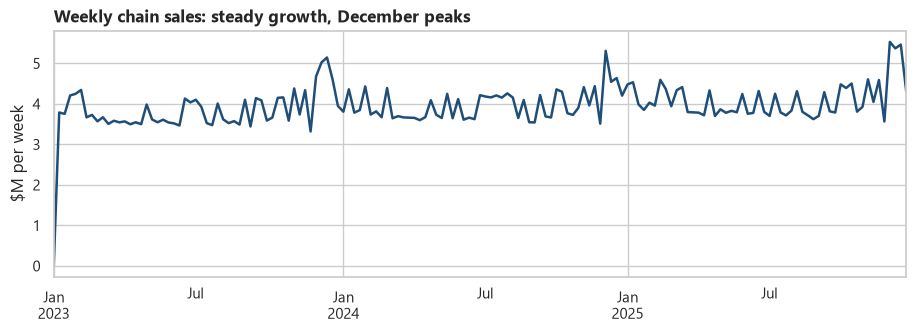

In [3]:
weekly = hist.set_index("date").sales.resample("W-SUN").sum().loc[:"2025-12-28"]
ax = (weekly / 1e6).plot(figsize=(11, 3.2), color="#1F4E79", lw=1.8)
ax.set_ylabel("$M per week"); ax.set_xlabel("")
ax.set_title("Weekly chain sales: steady growth, December peaks", loc="left", fontweight="bold");

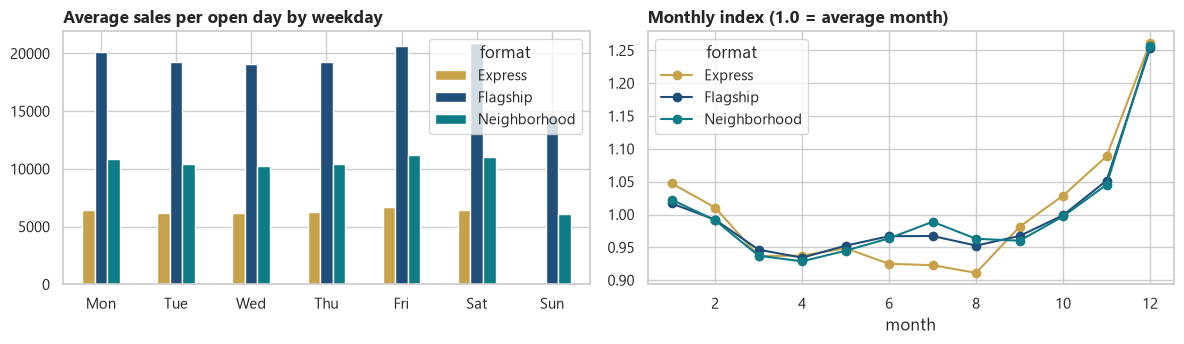

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
dow = open_days.assign(weekday=open_days.date.dt.day_name().str[:3]).groupby(["format", "weekday"]).sales.mean().unstack(0)
dow.loc[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]].plot.bar(ax=ax[0], rot=0, color=["#C8A24A", "#1F4E79", "#0E7C86"])
ax[0].set_title("Average sales per open day by weekday", loc="left", fontweight="bold"); ax[0].set_xlabel("")
mon = open_days.groupby([open_days.date.dt.month, "format"]).sales.mean().unstack()
(mon / mon.mean()).plot(ax=ax[1], marker="o", color=["#C8A24A", "#1F4E79", "#0E7C86"])
ax[1].set_title("Monthly index (1.0 = average month)", loc="left", fontweight="bold"); ax[1].set_xlabel("month")
plt.tight_layout()

Express stores are closed on Sundays; Flagships keep more Sunday trade. December is about 20% above an average month for every format.

## 2. Promotions: naive vs controlled

In [5]:
naive = open_days.groupby("promo").sales.mean()
print(f"Naive comparison, promo days vs other days: {naive[1] / naive[0] - 1:+.1%}")
drv = pd.read_csv("../data_clean/driver_effects.csv")
drv[["group", "effect", "estimated", "ci_low", "ci_high", "true"]]

Naive comparison, promo days vs other days: +23.2%


,group,effect,estimated,ci_low,ci_high,true
0,Promotions,"Promotion lift, Neighborhood (basic assortment)",0.178,0.176,0.181,0.180
1,Promotions,"Promotion lift, Flagship (basic assortment)",0.123,0.118,0.129,0.120
2,Promotions,"Promotion lift, Express (basic assortment)",0.249,0.245,0.253,0.250
3,Promotions,"Extra promo lift, extended assortment",0.031,NaN,NaN,0.030
4,Promotions,Loyalty programme (promo2),0.038,0.034,0.042,0.040
5,Calendar,"Payday (1st-3rd, 15th-16th)",0.061,0.060,0.063,0.060
6,Calendar,Day before a closed holiday,0.178,0.170,0.186,0.180
7,Calendar,Two days before a closed holiday,0.087,0.080,0.094,0.080
8,Calendar,Open public holiday,-0.178,-0.182,-0.174,-0.180
9,Calendar,"School holiday, Neighborhood",0.051,0.049,0.054,0.050


The naive comparison mixes the promotion with *where* and *when* it ran (formats differ in lift, promo weeks cluster before Thanksgiving and in December). The fixed-effects regression in `scripts/drivers.py` separates these, and its estimates land on the values built into the simulation, which shows the method recovers real effects.

## 3. Forecast accuracy (rolling backtest, three 6-week windows of 2025)

In [6]:
acc = pd.read_csv("../data_clean/accuracy_by_model.csv")
acc.pivot(index="model", columns="fold", values="WAPE").loc[["naive", "prophet", "gbm", "ensemble"]]

fold,1,2,3,all
model,,,,
naive,0.130,0.088,0.136,0.119
prophet,0.059,0.059,0.064,0.061
gbm,0.060,0.066,0.064,0.063
ensemble,0.058,0.059,0.060,0.059


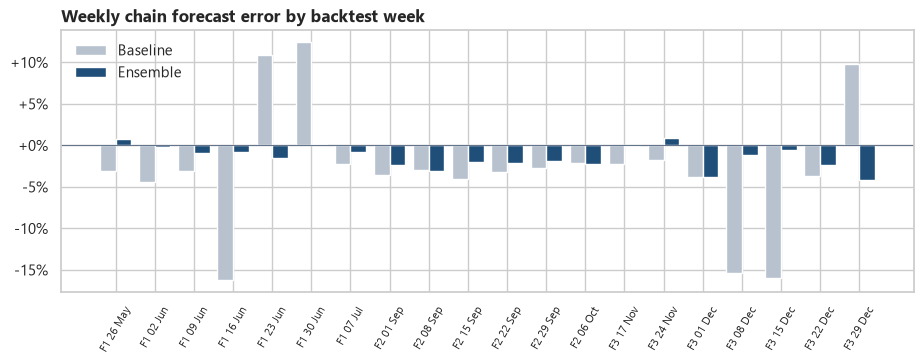

In [7]:
bt = pd.read_csv("../data_clean/backtest_predictions.csv", parse_dates=["date"])
u = bt[bt.usable == 1].assign(week=lambda x: x.date.dt.to_period("W-SUN").dt.start_time)
wk = u.groupby(["fold", "week"])[["sales", "naive", "ensemble"]].sum()
err = pd.DataFrame({"Baseline": (wk.naive / wk.sales - 1), "Ensemble": (wk.ensemble / wk.sales - 1)}).reset_index()
fig, ax = plt.subplots(figsize=(11, 3.4))
for i, (name, color) in enumerate([("Baseline", "#B8C2CF"), ("Ensemble", "#1F4E79")]):
    ax.bar(range(len(err)) if i == 0 else [x + 0.4 for x in range(len(err))], err[name], width=0.4, color=color, label=name)
ax.axhline(0, color="#64748B", lw=0.8)
ax.set_xticks([x + 0.2 for x in range(len(err))], [f"F{f} {w:%d %b}" for f, w in zip(err.fold, err.week)], rotation=60, fontsize=8)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:+.0%}"))
ax.legend(frameon=False); ax.set_title("Weekly chain forecast error by backtest week", loc="left", fontweight="bold");

The baseline misses whenever last year's promotion or holiday calendar differs from this year's; the models use the actual calendar and stay within a few percent each week.

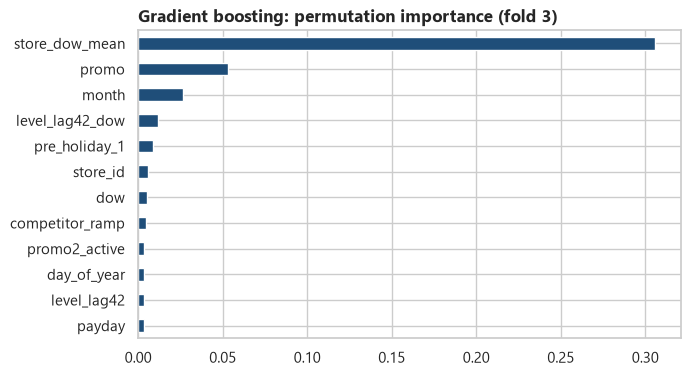

In [8]:
imp = pd.read_csv("../data_clean/feature_importance.csv").head(12)
ax = imp.iloc[::-1].plot.barh(x="feature", y="importance", legend=False, color="#1F4E79", figsize=(7, 4))
ax.set_title("Gradient boosting: permutation importance (fold 3)", loc="left", fontweight="bold"); ax.set_ylabel("");

## 4. The 2026 forecast

In [9]:
fc = pd.read_csv("../data_clean/forecast_2026.csv", parse_dates=["date"])
ly = hist[(hist.date >= "2025-01-01") & (hist.date <= "2025-02-11")].sales.sum()
print(f"Forecast 1 Jan - 11 Feb 2026: ${fc.forecast.sum() / 1e6:.2f}M  (P10 ${fc.p10.sum() / 1e6:.2f}M - P90 ${fc.p90.sum() / 1e6:.2f}M)")
print(f"Same dates 2025: ${ly / 1e6:.2f}M  ->  {fc.forecast.sum() / ly - 1:+.1%}")
by_fmt = fc.merge(pd.read_csv("../data_clean/stores.csv")[["store_id", "format"]]).groupby("format").forecast.sum()
(by_fmt / 1e6).round(2)

Forecast 1 Jan - 11 Feb 2026: $25.30M  (P10 $22.34M - P90 $26.84M)
Same dates 2025: $24.33M  ->  +4.0%


format
Express         3.890
Flagship        4.250
Neighborhood   17.170
Name: forecast, dtype: float64

## Takeaways
* The ensemble of Prophet and gradient boosting cuts forecast error (WAPE) roughly in half compared with "same weekday last year", and stays accurate through Thanksgiving and Christmas.
* The biggest controllable driver is promotions, and the lift depends on the format: Express stores respond about twice as strongly as Flagships.
* Calendar effects (payday, the day before a closed holiday, school breaks) are worth planning stock and staff around.
* A new competitor nearby costs about a tenth of a store's sales, more when it opens closer.
* The 2026 outlook is about 4% above the same weeks of 2025, in line with the underlying growth rate.